In [ ]:

import os
import numpy as np
import math
import pymc as pm
import pymc_bart as pmb
from pymc_bart.pgbart import PGBART
from numba import njit,set_num_threads
import scipy as sp


# ==========================================
# 1. THE NUMBA ROULETTE WHEEL (SPARSITY)
# ==========================================
@njit(cache=True)
def sample_feature(alpha_vec):
    total_weight = np.sum(alpha_vec)
    r = np.random.uniform(0.0, total_weight)
    cumulative = 0.0
    for i in range(len(alpha_vec)):
        cumulative += alpha_vec[i]
        if r <= cumulative:
            return i
    return len(alpha_vec) - 1

@njit(cache=True)
def get_split_counts(F, num_features):
    counts = np.zeros(num_features, dtype=np.int32)
    m_trees = F.shape[0]
    max_nodes = F.shape[1]
    for m in range(m_trees):
        for i in range(max_nodes):
            feat = F[m, i]
            if feat != -1: counts[feat] += 1
    return counts

# ==========================================
# 2. THE MUTATIONS
# ==========================================
@njit(cache=True)
def get_active_leaves(F_tree, current_node_count):
    leaves = np.empty(current_node_count, dtype=np.int16)
    leaf_count = 0
    for i in range(current_node_count):
        if F_tree[i] == -1:
            leaves[leaf_count] = i
            leaf_count += 1
    return leaves[:leaf_count]

@njit(cache=True)
def propose_grow(tree_idx, X, F, T, L, R, V, D, node_counts, alpha_vec, leaf_prior_std):
    current_count = node_counts[tree_idx]
    leaves = get_active_leaves(F[tree_idx], current_count)
    if current_count >= F.shape[1] - 1: return False, -1 
        
    random_idx = np.random.randint(0, len(leaves))
    leaf_to_split = leaves[random_idx]
    
    # NEW: Sparsity-aware feature selection
    split_feature = sample_feature(alpha_vec)
    feat_min, feat_max = np.min(X[:, split_feature]), np.max(X[:, split_feature])
    split_value = np.random.uniform(feat_min, feat_max)
    
    left_child_idx, right_child_idx = current_count, current_count + 1
    
    F[tree_idx, leaf_to_split] = split_feature
    T[tree_idx, leaf_to_split] = split_value
    L[tree_idx, leaf_to_split] = left_child_idx
    R[tree_idx, leaf_to_split] = right_child_idx
    F[tree_idx, left_child_idx] = -1
    F[tree_idx, right_child_idx] = -1
    
    # NEW: Update the Depth pointer
    parent_depth = D[tree_idx, leaf_to_split]
    D[tree_idx, left_child_idx] = parent_depth + 1
    D[tree_idx, right_child_idx] = parent_depth + 1

    # NEW: Inherit parent's value and add noise to the new leaves!
    parent_val = V[tree_idx, leaf_to_split]
    V[tree_idx, left_child_idx] = parent_val + np.random.normal(0.0, leaf_prior_std)
    V[tree_idx, right_child_idx] = parent_val + np.random.normal(0.0, leaf_prior_std)
    # V[tree_idx, left_child_idx] = np.random.normal(0.0, leaf_prior_std)
    # V[tree_idx, right_child_idx] = np.random.normal(0.0, leaf_prior_std)
    
    
    node_counts[tree_idx] += 2
    return True, leaf_to_split

@njit(cache=True)
def get_prunable_nodes(F_tree, L_tree, R_tree, current_node_count):
    prunable = np.empty(current_node_count, dtype=np.int16)
    count = 0
    for i in range(current_node_count):
        if F_tree[i] != -1:
            left, right = L_tree[i], R_tree[i]
            if left != -1 and right != -1:
                if F_tree[left] == -1 and F_tree[right] == -1:
                    prunable[count] = i
                    count += 1
    return prunable[:count]

@njit(cache=True)
def propose_prune(tree_idx, F, L, R, node_counts):
    current_count = node_counts[tree_idx]
    prunable_nodes = get_prunable_nodes(F[tree_idx], L[tree_idx], R[tree_idx], current_count)
    if len(prunable_nodes) == 0: return False, -1, -1
        
    random_idx = np.random.randint(0, len(prunable_nodes))
    node_to_prune = prunable_nodes[random_idx]
    old_feature = F[tree_idx, node_to_prune]
    
    F[tree_idx, node_to_prune] = -1
    return True, node_to_prune, old_feature

@njit(cache=True)
def get_internal_nodes(F_tree, current_node_count):
    internal = np.empty(current_node_count, dtype=np.int16)
    count = 0
    for i in range(current_node_count):
        if F_tree[i] != -1:
            internal[count] = i
            count += 1
    return internal[:count]

@njit(cache=True)
def propose_change(tree_idx, X, F, T, node_counts, alpha_vec):
    current_count = node_counts[tree_idx]
    internal_nodes = get_internal_nodes(F[tree_idx], current_count)
    if len(internal_nodes) == 0: return False, -1, -1, 0.0
        
    random_idx = np.random.randint(0, len(internal_nodes))
    node_to_change = internal_nodes[random_idx]
    
    old_feature = F[tree_idx, node_to_change]
    old_threshold = T[tree_idx, node_to_change]
    
    # NEW: Sparsity-aware feature selection
    new_feature = sample_feature(alpha_vec)
    feat_min, feat_max = np.min(X[:, new_feature]), np.max(X[:, new_feature])
    new_threshold = np.random.uniform(feat_min, feat_max)
    
    F[tree_idx, node_to_change] = new_feature
    T[tree_idx, node_to_change] = new_threshold
    
    return True, node_to_change, old_feature, old_threshold


@njit(cache=True)
def propose_leaf_change(tree_idx, F, V, node_counts, leaf_prior_std):
    current_count = node_counts[tree_idx]
    leaves = get_active_leaves(F[tree_idx], current_count)
    if len(leaves) == 0: return False, -1, 0.0
    
    random_idx = np.random.randint(0, len(leaves))
    leaf_to_change = leaves[random_idx]
    
    old_val = V[tree_idx, leaf_to_change]
    
    # Propose a random walk jump for the latent score
    # new_val = old_val + np.random.normal(0.0, leaf_prior_std)
    new_val = np.random.normal(0.0, leaf_prior_std)
    V[tree_idx, leaf_to_change] = new_val
    
    return True, leaf_to_change, old_val

@njit(fastmath=True)
def propose_leaf_change(m, F, V, node_counts, leaf_prior_std):
    # 1. Identify the valid terminal nodes
    # (Assuming you have logic here to pick a random leaf)
    mutated_node = ... 
    
    old_v = V[m, mutated_node]
    
    # 2. Execute the Random Walk
    step_size = 0.1  # Tune this if acceptance rates are too high/low
    new_v = old_v + np.random.normal(0.0, step_size)
    V[m, mutated_node] = new_v
    
    # 3. Calculate the Prior Penalty (Log-Ratio)
    # This penalizes the walk if it moves further away from 0.0
    var = leaf_prior_std ** 2
    penalty = (-0.5 * (new_v ** 2) / var) - (-0.5 * (old_v ** 2) / var)
    
    # Return the penalty as a 4th argument
    return True, mutated_node, old_v, penalty

# ==========================================
# 3. LIKELIHOOD AND PRIORS
# ==========================================
@njit(cache=True)
def get_tree_prediction(X, F_tree, T_tree, L_tree, R_tree, V_tree):
    n_rows = X.shape[0]
    preds = np.zeros(n_rows, dtype=np.float32)
    for i in range(n_rows):
        node = 0
        while F_tree[node] != -1:
            if X[i, F_tree[node]] <= T_tree[node]:
                node = L_tree[node]
            else:
                node = R_tree[node]
        preds[i] = V_tree[node]
    return preds

@njit(cache=True)
def calc_probit_loglik(Y, partial_pred, tree_pred):
    n_rows = Y.shape[0]
    log_lik = 0.0
    sqrt2 = 1.4142135623730951 
    for i in range(n_rows):
        eta = partial_pred[i] + tree_pred[i]
        p = 0.5 * (1.0 + math.erf(eta / sqrt2))
        if p < 1e-12: p = 1e-12
        elif p > 1.0 - 1e-12: p = 1.0 - 1e-12
        if Y[i] == 1: log_lik += math.log(p)
        else: log_lik += math.log(1.0 - p)
    return log_lik

@njit(cache=True)
def calc_grow_prior_ratio(node_depth, leaf_priors):
    # SAFETY 1: If the tree tries to grow deeper than the prior allows, crush it.
    if node_depth + 1 >= len(leaf_priors):
        return -1e9  # Massive negative log-penalty (guarantees rejection)
        
    p_leaf_d = leaf_priors[node_depth]
    p_leaf_d_plus_1 = leaf_priors[node_depth + 1]
    
    p_split = 1.0 - p_leaf_d
    
    # SAFETY 2: Prevent Division by Zero or Log(0)
    if p_leaf_d <= 0.0 or p_split <= 0.0:
        return -1e9
        
    prior_ratio = (p_split * (p_leaf_d_plus_1 ** 2)) / p_leaf_d
    return math.log(prior_ratio)

# ==========================================
# 4. THE MASTER ROUTER
# ==========================================
# @njit(cache=True)
# def mcmc_sweep(X, Y, F, T, L, R, V, D, node_counts, sum_trees, alpha_vec, leaf_priors):
#     m_trees = F.shape[0]
    
#     for m in range(m_trees):
#         old_tree_pred = get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m])
#         partial_pred = sum_trees - old_tree_pred
#         old_ll = calc_probit_loglik(Y, partial_pred, old_tree_pred)
        
#         step_type = np.random.random()
#         mutation_type = -1  
#         success = False
#         penalty = 0.0
        
#         if step_type < 0.25:
#             success, mutated_node = propose_grow(m, X, F, T, L, R, V, D, node_counts, alpha_vec)
#             if success: penalty = calc_grow_prior_ratio(D[m, mutated_node], leaf_priors)
#             mutation_type = 0
#         elif step_type < 0.50:
#             success, mutated_node, old_feat = propose_prune(m, F, L, R, node_counts)
#             if success: penalty = -calc_grow_prior_ratio(D[m, mutated_node], leaf_priors)
#             mutation_type = 1
#         elif step_type < 0.75:
#             success, mutated_node, old_feat, old_thresh = propose_change(m, X, F, T, node_counts, alpha_vec)
#             mutation_type = 2
#         else:
#             success, mutated_node, old_v = propose_leaf_change(m, F, V, node_counts)
#             mutation_type = 3
            
#         if not success: continue
            
#         new_tree_pred = get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m])
#         new_ll = calc_probit_loglik(Y, partial_pred, new_tree_pred)
        
#         # Metropolis-Hastings Ratio (Likelihood Delta + Prior Penalties)
#         log_alpha = (new_ll - old_ll) + penalty
#         accept = math.log(np.random.random()) < log_alpha
        
#         if accept:
#             sum_trees[:] = partial_pred + new_tree_pred
#         else:
#             # REJECT IT: Revert the memory arrays
#             if mutation_type == 0:
#                 F[m, mutated_node] = -1
#                 node_counts[m] -= 2
#             elif mutation_type == 1:
#                 F[m, mutated_node] = old_feat
#             elif mutation_type == 2:
#                 F[m, mutated_node] = old_feat
#                 T[m, mutated_node] = old_thresh
#             elif mutation_type == 3:
#                 V[m, mutated_node] = old_v  # NEW: Revert the leaf value!

@njit(cache=True)
def mcmc_fractional_sweep(X, Y, F, T, L, R, V, D, node_counts, 
                          sum_trees, alpha_vec, 
                          leaf_priors, leaf_prior_std,
                          update_fraction=0.1):
    m_trees = F.shape[0]
    
    # 1. Determine how many trees to mutate
    n_to_update = max(1, int(m_trees * update_fraction))
    
    # 2. Creat a shuffled array of tree indices
    indices = np.arange(m_trees)
    np.random.shuffle(indices)
    trees_to_update = indices[:n_to_update]
    
    # 3. Only loop through the chosen subset
    for m in trees_to_update:
        old_tree_pred = get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m])
        partial_pred = sum_trees - old_tree_pred
        old_ll = calc_probit_loglik(Y, partial_pred, old_tree_pred)
        
        step_type = np.random.random()
        mutation_type = -1  
        success = False
        penalty = 0.0
        
        if step_type < 0.25:
            success, mutated_node = propose_grow(m, X, F, T, L, R, V, D, node_counts, alpha_vec, leaf_prior_std)
            if success: penalty = calc_grow_prior_ratio(D[m, mutated_node], leaf_priors)
            mutation_type = 0
        elif step_type < 0.50:
            success, mutated_node, old_feat = propose_prune(m, F, L, R, node_counts)
            if success: penalty = -calc_grow_prior_ratio(D[m, mutated_node], leaf_priors)
            mutation_type = 1
        elif step_type < 0.75:
            success, mutated_node, old_feat, old_thresh = propose_change(m, X, F, T, node_counts, alpha_vec)
            mutation_type = 2
        else:
            success, mutated_node, old_v, leaf_penalty = propose_leaf_change(m, F, V, node_counts, leaf_prior_std)
            if success: 
                penalty = leaf_penalty
            mutation_type = 3
            # success, mutated_node, old_v = propose_leaf_change(m, F, V, node_counts, leaf_prior_std)
            # mutation_type = 3
            
        if not success: continue
            
        new_tree_pred = get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m])
        new_ll = calc_probit_loglik(Y, partial_pred, new_tree_pred)
        
        log_alpha = (new_ll - old_ll) + penalty
        accept = math.log(np.random.random()) < log_alpha
        
        if accept:
            sum_trees[:] = partial_pred + new_tree_pred
        else:
            if mutation_type == 0:
                F[m, mutated_node] = -1
                node_counts[m] -= 2
            elif mutation_type == 1:
                F[m, mutated_node] = old_feat
            elif mutation_type == 2:
                F[m, mutated_node] = old_feat
                T[m, mutated_node] = old_thresh
            elif mutation_type == 3:
                V[m, mutated_node] = old_v
            sum_trees[:] = partial_pred + old_tree_pred

# ==========================================
# 5. PYTHON API HANDOFF
# ==========================================
class FastTreeState:
    def __init__(self, m_trees, init_mean, max_nodes=255):
        self.m_trees = m_trees
        self.max_nodes = max_nodes
        self.F = np.full((m_trees, max_nodes), -1, dtype=np.int16)
        self.L = np.full((m_trees, max_nodes), -1, dtype=np.int16)
        self.R = np.full((m_trees, max_nodes), -1, dtype=np.int16)
        
        # THE FIX: Root node starts at Depth 1 to match PyMC's prior array
        self.D = np.ones((m_trees, max_nodes), dtype=np.int8) 
        
        self.T = np.zeros((m_trees, max_nodes), dtype=np.float32)
        self.V = np.zeros((m_trees, max_nodes), dtype=np.float32)
        self.node_counts = np.ones(m_trees, dtype=np.int16)
        self.V[:, 0] = init_mean / m_trees


class FastSurvPGBART(PGBART):
    def __init__(self, vars, target_x=None, 
                 target_y=None, use_sparsity=True, 
                 update_fraction=1.0, k=2,
                 return_estimates=False, *args, **kwargs):
        # 1. Initialize the parent class to set up the PyMC hooks
        super().__init__(vars, *args, **kwargs)
        
        self.use_sparsity = use_sparsity
        self.update_fraction = update_fraction
        # self.return_estimates = return_estimates
        
        # 2. THE EXPLICIT OVERRIDE: 
        # Use the injected massive data, or fall back to the graph's self.X / self.Y
        # actual_X = target_x if target_x is not None else self.X
        # actual_Y = target_y if target_y is not None else self.Y
        if target_x is None or target_y is None or return_estimates == True:
            actual_X = self.X
            actual_Y = self.Y
            self.return_estimates = True
            print("returning estimates")
        else:
            self.return_estimates = False
            actual_X = target_x
            actual_Y=target_y
        
        # 3. Setup the C-Engine memory
        base_prob = np.clip(actual_Y.mean(), 1e-5, 1.0 - 1e-5)
        latent_init = sp.stats.norm.ppf(base_prob)
        self.c_tree_state = FastTreeState(m_trees=self.m, init_mean=latent_init)
        
        self.k = 1.0 # Or whatever tuning you want (lower = less shrinkage)
        self.leaf_prior_std = np.float32(3.0 / (self.k * np.sqrt(self.m)))

        self.numba_X = np.copy(np.ascontiguousarray(actual_X))
        self.numba_Y = np.copy(np.ascontiguousarray(actual_Y))
        
        self.flat_sum_trees = np.full(actual_X.shape[0], latent_init, dtype=np.float32)
        
        self.alpha_vec = np.ones(actual_X.shape[1], dtype=np.float32)
        self.numba_leaf_priors = np.array(self.prior_prob_leaf_node, dtype=np.float32)
        self.stats_dtypes = [{
            "variable_inclusion": np.ndarray,
            "tune": bool,
            "F_trees": np.ndarray,
            "T_trees": np.ndarray,
            "L_trees": np.ndarray,
            "R_trees": np.ndarray,
            "V_trees": np.ndarray,
            "node_counts": np.ndarray
        }]

    def astep(self, q0):
        mcmc_fractional_sweep(
            self.numba_X, self.numba_Y, 
            self.c_tree_state.F, self.c_tree_state.T, 
            self.c_tree_state.L, self.c_tree_state.R, 
            self.c_tree_state.V, self.c_tree_state.D, 
            self.c_tree_state.node_counts,
            self.flat_sum_trees, 
            self.alpha_vec, self.numba_leaf_priors,
            self.leaf_prior_std,
            self.update_fraction # <-- Pass to C-Loop
        )
        
        var_counts = get_split_counts(self.c_tree_state.F, self.num_variates)
        
        if self.tune and self.use_sparsity:
            if self.iter > self.m:
                self.alpha_vec += var_counts.astype(np.float32)
        
        stats = {
            "variable_inclusion": var_counts, 
            "tune": self.tune,
            "F_trees": self.c_tree_state.F.copy(),
            "T_trees": self.c_tree_state.T.copy(),
            "L_trees": self.c_tree_state.L.copy(),
            "R_trees": self.c_tree_state.R.copy(),
            "V_trees": self.c_tree_state.V.copy(),
            "node_counts": self.c_tree_state.node_counts.copy()
        }
        
        
        if self.return_estimates == True:
            self.sum_trees[0, 0, :] = self.flat_sum_trees
            return self.sum_trees, [stats]
        else:
            return np.zeros(1), [stats]
            


@njit(fastmath=True, cache=True)
def _fast_predict_trace(X, F, T, L, R, V):
    n_samples = F.shape[0]
    m_trees = F.shape[1]
    n_obs = X.shape[0]
    
    # Output array: (samples, observations)
    preds = np.zeros((n_samples, n_obs), dtype=np.float32)
    
    for s in range(n_samples):
        for i in range(n_obs):
            tree_sum = 0.0
            
            # Drop this observation down all M trees in this specific sample
            for m in range(m_trees):
                node = 0
                
                # Walk the tree until we hit a leaf (F == -1)
                while F[s, m, node] != -1:
                    feat = F[s, m, node]
                    val = X[i, feat]
                    
                    if val <= T[s, m, node]:
                        node = L[s, m, node]
                    else:
                        node = R[s, m, node]
                        
                tree_sum += V[s, m, node]
                
            preds[s, i] = tree_sum
            
    return preds

def predict_out_of_sample(trace, X_new, m_trees=50, max_nodes=255):
    """
    Extracts the serialized forest topology from a PyMC trace, 
    bypasses all ArviZ dimension quirks, and generates predictions.
    """
    stats = trace.sample_stats
    
    # 1. Melt whatever shape ArviZ created down into a flat 1D vector
    F_flat = stats["F_trees"].values.ravel()
    T_flat = stats["T_trees"].values.ravel()
    L_flat = stats["L_trees"].values.ravel()
    R_flat = stats["R_trees"].values.ravel()
    V_flat = stats["V_trees"].values.ravel()
    
    # 2. Mathematically deduce the number of samples using the total element count
    # 25,500,000 // (50 * 255) = 2000
    n_samples = F_flat.size // (m_trees * max_nodes)
    
    # 3. Forcefully rebuild the pristine 3D tensors: (samples, trees, nodes)
    # F = F_flat.reshape(n_samples, m_trees, max_nodes)
    # T = T_flat.reshape(n_samples, m_trees, max_nodes)
    # L = L_flat.reshape(n_samples, m_trees, max_nodes)
    # R = R_flat.reshape(n_samples, m_trees, max_nodes)
    # V = V_flat.reshape(n_samples, m_trees, max_nodes)
    # 3. Forcefully rebuild pristine 3D tensors and lock the memory layouts
    F = np.ascontiguousarray(F_flat.reshape(n_samples, m_trees, max_nodes)).astype(np.int16)
    T = np.ascontiguousarray(T_flat.reshape(n_samples, m_trees, max_nodes)).astype(np.float32)
    L = np.ascontiguousarray(L_flat.reshape(n_samples, m_trees, max_nodes)).astype(np.int16)
    R = np.ascontiguousarray(R_flat.reshape(n_samples, m_trees, max_nodes)).astype(np.int16)
    V = np.ascontiguousarray(V_flat.reshape(n_samples, m_trees, max_nodes)).astype(np.float32)
    
    # 4. Ensure X is contiguous for the Numba C-engine
    X_numba = np.ascontiguousarray(X_new, dtype=np.float64)
    n_obs = X_new.shape[0]
    
    print(f"Processing: Dropping {n_obs} rows down {n_samples} historical forests...")
    
    # 5. Calculate continuous latent scores using the C-dropper
    latent_scores = _fast_predict_trace(X_numba, F, T, L, R, V)
    
    # 6. Map latent scores back to True Probabilities via the Probit link
    probabilities = sp.stats.norm.cdf(latent_scores)
    
    return probabilities

In [68]:
import matplotlib.pyplot as plt

# ==========================================
# 4. THE TEST RUN
# ==========================================
if __name__ == "__main__":
    print("Generating dummy data...")
    N= 400
    X_dummy = np.random.normal(size=(N, 10))
    p = sp.stats.norm.cdf(X_dummy[:,0] * .2 + X_dummy[:,3] * 1.2)
    Y_dummy = np.random.binomial(1, p, size=N)

    import pytensor.tensor as pt

    # ... [Data Generation] ...
    import multiprocessing as mp

    print("Building model graph...")
    with pm.Model() as test_model:
        # ENGINE_MODE = "native" 
        ENGINE_MODE = "fast_vanilla" 
        # ENGINE_MODE = "fast_sparse" 


        # test no return estimates
        # requres this hack of submitting a 1D array to the BART object itself
        # trees = pmb.BART("trees", X=np.zeros((1,X_dummy.shape[1])), Y=np.zeros(1), m=200)
        trees = pmb.BART("trees", X=X_dummy, Y=Y_dummy, m=50)
        
        # THE FIX: Translate latent tree scores to probabilities (Probit Link)
        prob = 0.5 * (1.0 + pt.erf(trees / pt.sqrt(2.0)))
        
        # THE FIX: Use Bernoulli for binary classification, NOT Normal
        obs = pm.Bernoulli("obs", p=prob, observed=Y_dummy)

        # ==========================================
        # THE MASTER TOGGLE
        # ==========================================

        
        
        if ENGINE_MODE == "native":
            print("\n[CONFIG] Using Baseline PyMC Particle Gibbs BART...")
            custom_step = None
            
        elif ENGINE_MODE == "fast_vanilla":
            print("\n[CONFIG] Using Custom C-Engine (Uniform Feature)...")
            custom_step = FastSurvPGBART(
                vars=[trees], 
                use_sparsity=False, 
                update_fraction=.05,
                k=.1
                )
            
        elif ENGINE_MODE == "fast_sparse":
            print("\n[CONFIG] Using Custom C-Engine (Dirichlet Sparsity)...")
            custom_step = FastSurvPGBART(
                vars=[trees], 
                use_sparsity=True, 
                update_fraction=.1,
                )
            
        elif ENGINE_MODE == "fast_sparse_backdoor":
            print("\n[CONFIG] Using Custom C-Engine (Dirichlet Sparsity)...")
            custom_step = FastSurvPGBART(
                vars=[trees], 
                use_sparsity=True, 
                update_fraction=.1,
                target_x = X_dummy,
                target_y = Y_dummy,
                return_estimate = False
                )

        trace = pm.sample(
                draws=1000, 
                tune=5000, 
                chains=4, 
                cores=4,
                step=custom_step,  # If None, PyMC handles it
                # mp_ctx=mp.get_context("forkserver"),
                # blas_cores=1,
                compute_convergence_checks=False,
                progressbar=True,
                discard_tuned_samples=True
            )

Generating dummy data...
Building model graph...


Multiprocess sampling (4 chains in 4 jobs)
FastSurvPGBART: [trees]



[CONFIG] Using Custom C-Engine (Uniform Feature)...
returning estimates


Output()

Sampling 4 chains for 5_000 tune and 1_000 draw iterations (20_000 + 4_000 draws total) took 7 seconds.


Processing: Dropping 400 rows down 4000 historical forests...


(0.0, 1.0)

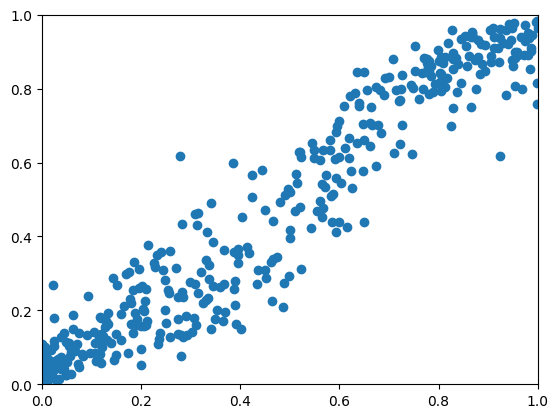

In [69]:
# plt.plot(p, trace.posterior["trees"].values.mean(0).mean)
preds = predict_out_of_sample(trace, X_dummy, m_trees=50)
plt.scatter(p,preds.mean(0))
# 47
plt.ylim(0,1)
plt.xlim(0,1)

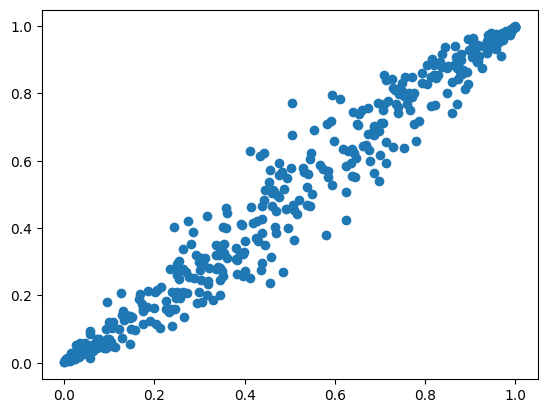

In [62]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression().fit(X_dummy, Y_dummy)
lg_pred = model.predict_proba(X_dummy)[:,1]
plt.scatter(p, lg_pred)

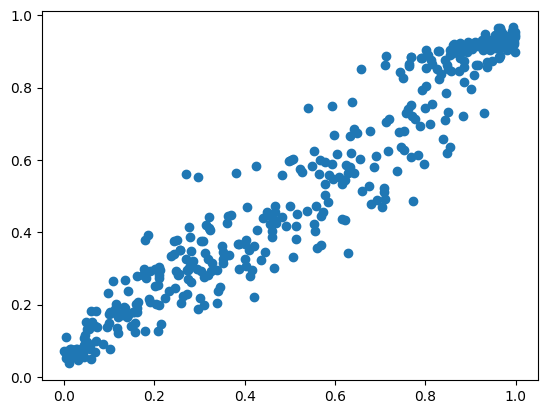

In [63]:
plt.scatter(lg_pred, preds.mean(0))

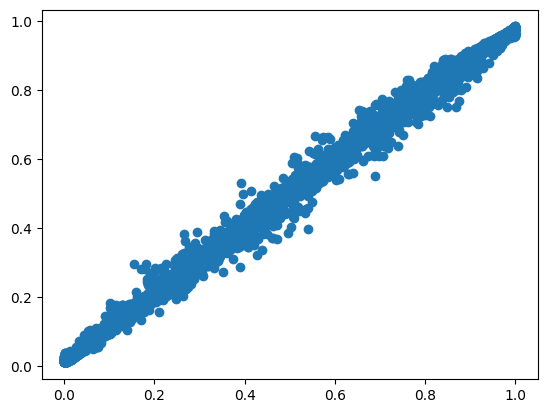

In [ ]:
probs = sp.stats.norm.cdf(trace.posterior.trees.values)
plt.scatter(p,probs.mean(0).mean(0))
# 43

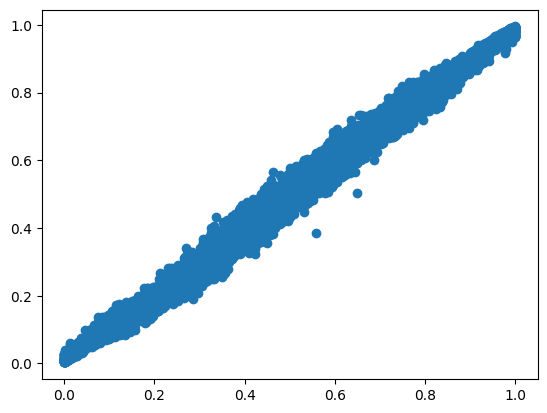

In [217]:
probs = sp.stats.norm.cdf(trace.posterior.trees.values)
plt.scatter(p,probs.mean(0).mean(0))
# 47

In [226]:
np.quantile(probs.mean(2).flatten(), [0.025,0.975])

array([0.49645651, 0.51221898])

In [164]:
# Look at the final inclusion counts across the chains
var_counts = trace.sample_stats["variable_inclusion"].values.sum(axis=(0, 1))
print("Variable Splits:", var_counts)

Variable Splits: [32044 20257 20370 68588 17260]


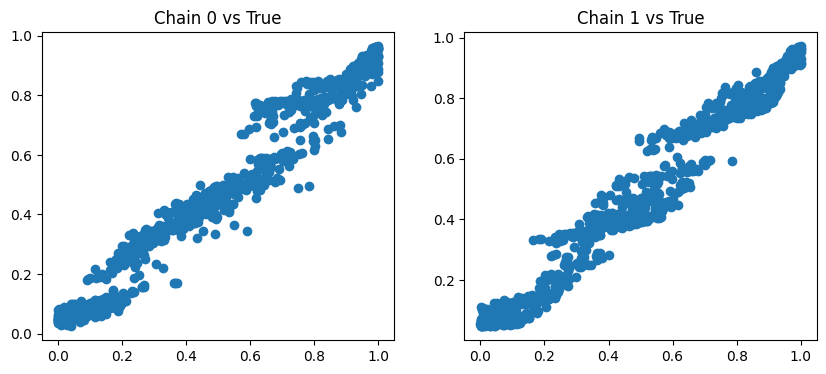

In [165]:
import matplotlib.pyplot as plt

probs_chain_0 = sp.stats.norm.cdf(trace.posterior.trees.isel(chain=0).values).mean(0)
probs_chain_1 = sp.stats.norm.cdf(trace.posterior.trees.isel(chain=1).values).mean(0)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title("Chain 0 vs True")
plt.scatter(p, probs_chain_0)

plt.subplot(1, 2, 2)
plt.title("Chain 1 vs True")
plt.scatter(p, probs_chain_1)
plt.show()

In [ ]:
@njit(cache=True)
def propose_grow_fake(tree_idx, X, F, T, L, R, V, node_counts):
    current_count = node_counts[tree_idx]
    leaves = get_active_leaves(F[tree_idx], current_count)
    if current_count >= F.shape[1] - 1: return False, -1 
        
    random_idx = np.random.randint(0, len(leaves))
    leaf_to_split = leaves[random_idx]
    
    num_features = X.shape[1]
    split_feature = np.random.randint(0, num_features)
    feat_min, feat_max = np.min(X[:, split_feature]), np.max(X[:, split_feature])
    split_value = np.random.uniform(feat_min, feat_max)
    
    left_child_idx, right_child_idx = current_count, current_count + 1
    
    F[tree_idx, leaf_to_split] = split_feature
    T[tree_idx, leaf_to_split] = split_value
    L[tree_idx, leaf_to_split] = left_child_idx
    R[tree_idx, leaf_to_split] = right_child_idx
    F[tree_idx, left_child_idx] = -1
    F[tree_idx, right_child_idx] = -1
    
    # Give the new leaves some random prediction values so the likelihood changes!
    V[tree_idx, left_child_idx] = np.random.normal(0, 0.5)
    V[tree_idx, right_child_idx] = np.random.normal(0, 0.5)
    
    node_counts[tree_idx] += 2
    return True, leaf_to_split
# =========================================
# 2. THE TEST RUN
# ==========================================
if __name__ == "__main__":
    print("\n--- Initializing Dummy Data & C-Memory ---")
    X_dummy = np.ascontiguousarray(np.random.normal(size=(1000, 5)))
    
    # We create a true relationship so the model has something to learn
    # If X0 > 0, higher chance of event (Y=1)
    true_eta = X_dummy[:, 0] * 1.5
    true_p = 0.5 * (1.0 + np.vectorize(math.erf)(true_eta / 1.414))
    Y_dummy = np.random.binomial(1, true_p)
    
    # Allocate a single tree for testing
    m_trees = 1
    max_nodes = 255
    F = np.full((m_trees, max_nodes), -1, dtype=np.int16)
    L = np.full((m_trees, max_nodes), -1, dtype=np.int16)
    R = np.full((m_trees, max_nodes), -1, dtype=np.int16)
    T = np.zeros((m_trees, max_nodes), dtype=np.float32)
    V = np.zeros((m_trees, max_nodes), dtype=np.float32)
    node_counts = np.ones(m_trees, dtype=np.int16)
    
    # Simulate partial predictions (the rest of the ensemble) being exactly 0
    partial_preds = np.zeros(1000, dtype=np.float32)
    
    print("\n[PHASE 1] Stump Likelihood")
    stump_preds = get_tree_prediction(X_dummy, F[0], T[0], L[0], R[0], V[0])
    stump_ll = calc_probit_loglik(Y_dummy, partial_preds, stump_preds)
    print(f" -> Stump Log-Likelihood: {stump_ll:.4f}")
    
    print("\n[PHASE 2] Mutating Tree (Grow)...")
    # We force it to grow until it splits on X0 (the true feature)
    while True:
        propose_grow_fake(0, X_dummy, F, T, L, R, V, node_counts)
        if F[0, 0] == 0: 
            break
        else:
            # Revert to stump if it picked the wrong feature
            F[0, 0] = -1
            node_counts[0] = 1

    print(f" -> Tree successfully split on Feature 0 (Threshold: {T[0,0]:.4f})")
    
    print("\n[PHASE 3] New Likelihood")
    new_preds = get_tree_prediction(X_dummy, F[0], T[0], L[0], R[0], V[0])
    print(new_preds[1:100])
    new_ll = calc_probit_loglik(Y_dummy, partial_preds, new_preds)
    print(f" -> Mutated Log-Likelihood: {new_ll:.4f}")
    
    ll_diff = new_ll - stump_ll
    print(f"\n[RESULT] Likelihood Delta: {ll_diff:+.4f}")
    if ll_diff > 0:
        print(" -> The mutation IMPROVED the model. Metropolis-Hastings will likely ACCEPT.")
    else:
        print(" -> The mutation WORSENED the model. Metropolis-Hastings will likely REJECT.")


--- Initializing Dummy Data & C-Memory ---

[PHASE 1] Stump Likelihood
 -> Stump Log-Likelihood: -693.1472

[PHASE 2] Mutating Tree (Grow)...
 -> Tree successfully split on Feature 0 (Threshold: -2.0260)

[PHASE 3] New Likelihood
[-0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.10594031 -0.00794347 -0.00794347 -0.00794347 -0.00794347
 -0.00794347 -0.00794347 -0.00794347 -0

array([0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1,
       1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
       0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1,
       1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0,
       0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1,
       1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1,
       1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,